# Setup

This project requires Python 3.7 or above:

In [6]:
import sys

assert sys.version_info >= (3, 7)

It also requires Scikit-Learn ≥ 1.0.1:

In [7]:
from packaging import version
import sklearn

assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

As we did in previous chapters, let's define the default font sizes to make the figures prettier:

In [8]:
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

And let's create the `images/training_linear_models` folder (if it doesn't already exist), and define the `save_fig()` function which is used through this notebook to save the figures in high-res for the book:

In [9]:
from pathlib import Path

IMAGES_PATH = Path() / "images" / "training_linear_models"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

In [10]:
import numpy as np

# Logistic Regression

## Estimating Probabilities

## Decision Boundaries

In [11]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
list(iris)

['data',
 'target',
 'frame',
 'target_names',
 'DESCR',
 'feature_names',
 'filename',
 'data_module']

In [10]:
print(iris.DESCR)  # extra code – it's a bit too long

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [11]:
iris.data.head(3)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2


In [9]:
iris.target.head(3)  # note that the instances are not shuffled

0    0
1    0
2    0
Name: target, dtype: int64

In [10]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

X = iris.data[["petal width (cm)"]].values
y = iris.target_names[iris.target] == 'virginica'
X_train, X_test, y_train, y_test = train_test_split(X, y)

log_reg = LogisticRegression()
log_reg.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


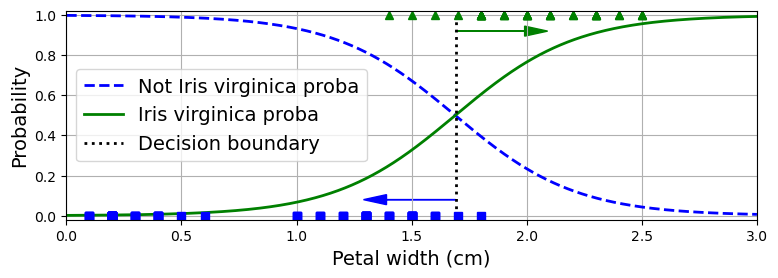

In [13]:
X_new = np.linspace(0, 3, 1000).reshape(-1, 1)  # reshape to get a column vector
y_proba = log_reg.predict_proba(X_new)
decision_boundary = X_new[y_proba[:, 1] >= 0.5][0, 0]

plt.figure(figsize=(8, 3))  # extra code – not needed, just formatting
plt.plot(X_new, y_proba[:, 0], "b--", linewidth=2,
         label="Not Iris virginica proba")
plt.plot(X_new, y_proba[:, 1], "g-", linewidth=2, label="Iris virginica proba")
plt.plot([decision_boundary, decision_boundary], [0, 1], "k:", linewidth=2,
         label="Decision boundary")

# extra code – this section beautifies and saves Figure 4–23
plt.arrow(x=decision_boundary, y=0.08, dx=-0.3, dy=0,
          head_width=0.05, head_length=0.1, fc="b", ec="b")
plt.arrow(x=decision_boundary, y=0.92, dx=0.3, dy=0,
          head_width=0.05, head_length=0.1, fc="g", ec="g")
plt.plot(X_train[y_train == 0], y_train[y_train == 0], "bs")
plt.plot(X_train[y_train == 1], y_train[y_train == 1], "g^")
plt.xlabel("Petal width (cm)")
plt.ylabel("Probability")
plt.legend(loc="center left")
plt.axis([0, 3, -0.02, 1.02])
plt.grid()
save_fig("logistic_regression_plot")

plt.show()

In [16]:
decision_boundary

1.6336336336336337

In [15]:
log_reg.predict([[1.7], [1.5]])

array([ True, False])

In [20]:
log_reg.predict_proba([[1.7], [1.5]])

array([[0.4340418 , 0.5659582 ],
       [0.62248441, 0.37751559]])

In [42]:
print(y_proba)

[[9.99830527e-01 1.69472583e-04]
 [9.99826087e-01 1.73912584e-04]
 [9.99821531e-01 1.78468887e-04]
 ...
 [8.34952640e-05 9.99916505e-01]
 [8.13634359e-05 9.99918637e-01]
 [7.92860340e-05 9.99920714e-01]]


In [32]:
len(y_proba[:, 1])

100000

In [ ]:
y_proba[:, 1] #The output shows the probablity of being virginica for each single data point of the 100000 data points

array([1.69472583e-04, 1.73912584e-04, 1.78468887e-04, ...,
       9.99916505e-01, 9.99918637e-01, 9.99920714e-01])

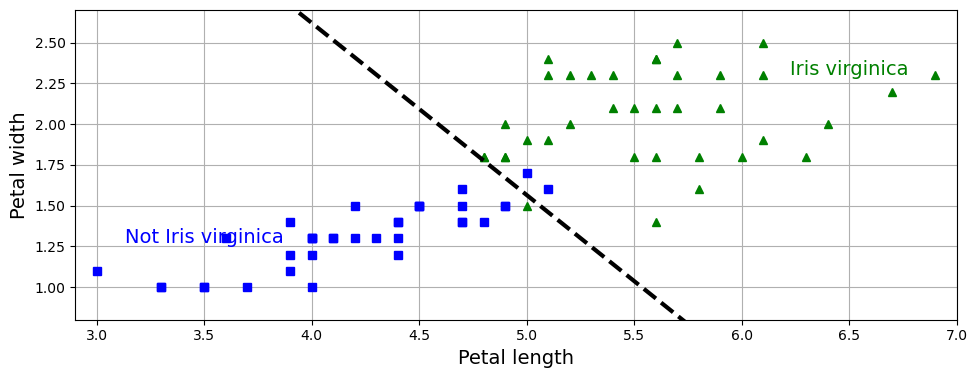

In [14]:
# extra code – this cell generates and saves Figure 4–24

X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = iris.target_names[iris.target] == 'virginica'
X_train, X_test, y_train, y_test = train_test_split(X, y)

log_reg = LogisticRegression(C=2)
log_reg.fit(X_train, y_train)

# for the contour plot
x0, x1 = np.meshgrid(np.linspace(2.9, 7, 500).reshape(-1, 1), #reshape(-1, 1) means that I am transpsoing the shape into 1 column and an infinte number of columns. since I have 1000 samples, I am choosing the -1 for rows which means infinite number of rows, which also means I do not care how many number of rows. And becuase I am transposing I am setting the number of columns to only one. (However, in a different case like when dealing with images, the transposing would look like this .reshape(1, -1), which means I want to have all of the images in one row, and I want to have an infinite number of columns, which also means I do not care how many columms I do have)
                     np.linspace(0.8, 2.7, 200).reshape(-1, 1))
X_new = np.c_[x0.ravel(), x1.ravel()]  #one instance per point on the figure #so what the function ravel() does is that it removes the containers, putting everying in one array. For example, if you have an array inisde of an array, ravel() removes all the other arrays and keeps everything in one big array. The ravel() function takes any multidimerntioal array(llike 2D or 3D array), and it always coverts the array into a 1D array
y_proba = log_reg.predict_proba(X_new)
zz = y_proba[:, 1].reshape(x0.shape) #since the length of y_proba[:, 1] is 100000, we are reshaping it(y_proba[:, 1]) in a 2D grid exactly like the 2D grid where x0 is stored

# for the decision boundary
left_right = np.array([2.9, 7])
boundary = -((log_reg.coef_[0, 0] * left_right + log_reg.intercept_[0])
             / log_reg.coef_[0, 1])

plt.figure(figsize=(10, 4))
plt.plot(X_train[y_train == 0, 0], X_train[y_train == 0, 1], "bs")
plt.plot(X_train[y_train == 1, 0], X_train[y_train == 1, 1], "g^")
#contour = plt.contour(x0, x1, zz, cmap=plt.cm.brg)
#plt.clabel(contour, inline=1)
plt.plot(left_right, boundary, "k--", linewidth=3)
plt.text(3.5, 1.27, "Not Iris virginica", color="b", ha="center")
plt.text(6.5, 2.3, "Iris virginica", color="g", ha="center")
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.axis([2.9, 7, 0.8, 2.7])
plt.grid()
save_fig("logistic_regression_contour_plot")
plt.show()

In [30]:
x0.shape

(200, 500)

In [35]:
x1.shape

(200, 500)

In [34]:
zz.shape

(200, 500)

In [ ]:
print(left_right) #the output of numpy arrays does not have to have a comma, so make it more like I am prininting the arrays individually
print(left_right[0])
print(left_right[1])

[2.9 7. ]
2.9
7.0


In [ ]:
print(y_proba)

[[9.99830527e-01 1.69472583e-04]
 [9.99826087e-01 1.73912584e-04]
 [9.99821531e-01 1.78468887e-04]
 ...
 [8.34952640e-05 9.99916505e-01]
 [8.13634359e-05 9.99918637e-01]
 [7.92860340e-05 9.99920714e-01]]


In [39]:
print(X_test.shape, y_test.shape)

(38, 2) (38,)


In [35]:
y_test.shape


(38,)

In [ ]:
ytest_proba = log_reg.predict_proba(X_test) #if you run this again, the output will probaility change to something else 

In [69]:
len(ytest_proba)

38

In [ ]:
print(np.round(ytest_proba, 2)) #it is easier to see the output when I am rounding to the 2th or less, but it seems like there are quiet a few that need to be rounded to the 3rd or more, because they are only showing 1. or 0.

[[0.67 0.33]
 [0.94 0.06]
 [0.87 0.13]
 [1.   0.  ]
 [1.   0.  ]
 [0.94 0.06]
 [0.16 0.84]
 [0.57 0.43]
 [0.75 0.25]
 [1.   0.  ]
 [1.   0.  ]
 [1.   0.  ]
 [0.81 0.19]
 [0.99 0.01]
 [0.99 0.01]
 [0.75 0.25]
 [1.   0.  ]
 [0.94 0.06]
 [0.57 0.43]
 [0.22 0.78]
 [0.94 0.06]
 [1.   0.  ]
 [0.38 0.62]
 [0.67 0.33]
 [0.38 0.62]
 [1.   0.  ]
 [0.47 0.53]
 [0.81 0.19]
 [0.38 0.62]
 [0.38 0.62]
 [0.75 0.25]
 [0.67 0.33]
 [0.38 0.62]
 [0.81 0.19]
 [0.87 0.13]
 [0.38 0.62]
 [0.29 0.71]
 [1.   0.  ]]


In [68]:
print(np.round(ytest_proba, 3))

[[0.666 0.334]
 [0.935 0.065]
 [0.867 0.133]
 [0.997 0.003]
 [0.997 0.003]
 [0.935 0.065]
 [0.157 0.843]
 [0.573 0.427]
 [0.748 0.252]
 [0.997 0.003]
 [0.997 0.003]
 [0.998 0.002]
 [0.815 0.185]
 [0.994 0.006]
 [0.991 0.009]
 [0.748 0.252]
 [0.996 0.004]
 [0.935 0.065]
 [0.573 0.427]
 [0.216 0.784]
 [0.935 0.065]
 [0.997 0.003]
 [0.378 0.622]
 [0.666 0.334]
 [0.378 0.622]
 [0.997 0.003]
 [0.475 0.525]
 [0.815 0.185]
 [0.378 0.622]
 [0.378 0.622]
 [0.748 0.252]
 [0.666 0.334]
 [0.378 0.622]
 [0.815 0.185]
 [0.867 0.133]
 [0.378 0.622]
 [0.291 0.709]
 [0.997 0.003]]


In [ ]:
accuracy_score = np.mean(y_test == ytest_proba)
print(accuracy_score)

In [76]:
#since I am getting the following error /var/folders/m_/gtpr2s5n57s1x1k6fp5ccxh40000gn/T/ipykernel_8263/1253393518.py:1: DeprecationWarning: elementwise comparison failed; this will raise an error in the future. accuracy_score = np.mean(y_proba == ytest_proba)
print(y_proba.dtype)
print(ytest_proba.dtype)

print(len(y_proba))
print(len(ytest_proba))

float64
float64
1000
38


In [24]:
ytest_pred = log_reg.predict(X_test) #if you run this again, the output will probaility change to something else 

In [84]:
print(ytest_pred) #it is easier to see the output when I am rounding to the 2th or less, but it seems like there are quiet a few that need to be rounded to the 3rd or more, because they are only showing 1. or 0.

[False False False False False False  True False False False False False
 False False False False False False False  True False False  True False
  True False  True False  True  True False False  True False False  True
  True False]


In [25]:
#since I am getting the following error before
print(y_test.dtype)
print(ytest_pred.dtype)

print(len(y_test))
print(len(ytest_pred))

bool
bool
38
38


In [26]:
accuracy_testscore = np.mean(y_test == ytest_pred)
print(accuracy_testscore)

0.9473684210526315


In [97]:
ytrain_pred = log_reg.predict(X_train)

#since I am getting the following error before
print(y_train.dtype)
print(ytrain_pred.dtype)

print(len(y_train))
print(len(ytrain_pred))

bool
bool
112
112


In [98]:
accuracy_trainscore = np.mean(y_train == ytrain_pred)
print(accuracy_trainscore)

0.9732142857142857


In this case, the model is performing better and with more accuracy on the training set than on the test set. The model might have overfitted 

The following day, I tried again with running the test model again and I thought I might get a different result this time, but I ended up getting a similar resilt, and the training set still performed better with more accuracy than the test set.

In [52]:
print(len(y_test))
len(X_test)

38


38

In [37]:
y_test

array([ True,  True, False, False,  True, False, False,  True, False,
       False, False, False, False, False, False, False, False, False,
        True,  True, False, False, False, False,  True,  True, False,
       False,  True,  True,  True,  True, False, False,  True, False,
       False, False])

In [49]:
X_test

array([[5.6, 2.2],
       [4.5, 1.7],
       [1.5, 0.2],
       [4.2, 1.3],
       [5. , 2. ],
       [1.5, 0.2],
       [1.4, 0.2],
       [5.1, 1.9],
       [4.8, 1.8],
       [4.2, 1.2],
       [1.5, 0.3],
       [1.5, 0.2],
       [4.6, 1.5],
       [1.4, 0.2],
       [4.5, 1.6],
       [4.1, 1. ],
       [4.6, 1.3],
       [1.2, 0.2],
       [6.7, 2. ],
       [6. , 2.5],
       [4.5, 1.5],
       [1.4, 0.3],
       [4.3, 1.3],
       [1.4, 0.2],
       [5.8, 2.2],
       [6.6, 2.1],
       [4.5, 1.5],
       [4.7, 1.2],
       [5.1, 2. ],
       [5.5, 1.8],
       [5.1, 1.8],
       [5.1, 1.5],
       [1.4, 0.2],
       [4.5, 1.3],
       [5.3, 1.9],
       [1.5, 0.1],
       [3.8, 1.1],
       [4.6, 1.4]])

In [40]:
x_pred = log_reg.predict(X_test)

In [46]:
print(x_pred.dtype)
print(len(x_pred))

print(y_test.dtype)
print(len(y_test))

accuracy = (x_pred == y_test).mean()
print(accuracy)

bool
38
bool
38
0.9473684210526315


In [ ]:
#Fixed the problem that I was facing #I was getting an error and followed by this advice "Reshape your data either using array.reshape(-1, 1) if your data has a single feature or array.reshape(1, -1) if it contains a single sample."

## Softmax Regression

In [ ]:
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = iris["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y)

softmax_reg = LogisticRegression(C=30)
softmax_reg.fit(X_train, y_train)

In [ ]:
softmax_reg.predict([[5, 2]])

In [ ]:
softmax_reg.predict_proba([[5, 2]]).round(2)

In [ ]:
# extra code – this cell generates and saves Figure 4–25

from matplotlib.colors import ListedColormap

custom_cmap = ListedColormap(["#fafab0", "#9898ff", "#a0faa0"])

x0, x1 = np.meshgrid(np.linspace(0, 8, 500).reshape(-1, 1),
                     np.linspace(0, 3.5, 200).reshape(-1, 1))
X_new = np.c_[x0.ravel(), x1.ravel()]

y_proba = softmax_reg.predict_proba(X_new)
y_predict = softmax_reg.predict(X_new)

zz1 = y_proba[:, 1].reshape(x0.shape)
zz = y_predict.reshape(x0.shape)

plt.figure(figsize=(10, 4))
plt.plot(X[y == 2, 0], X[y == 2, 1], "g^", label="Iris virginica")
plt.plot(X[y == 1, 0], X[y == 1, 1], "bs", label="Iris versicolor")
plt.plot(X[y == 0, 0], X[y == 0, 1], "yo", label="Iris setosa")

plt.contourf(x0, x1, zz, cmap=custom_cmap)
contour = plt.contour(x0, x1, zz1, cmap="hot")
plt.clabel(contour, inline=1)
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.legend(loc="center left")
plt.axis([0.5, 7, 0, 3.5])
plt.grid()
save_fig("softmax_regression_contour_plot")
plt.show()